# **TD 3: Économétrie appliquée**

### Lors de ce TD, nous allons analyser la fréquence des sinistres automobiles selon les caractéristiques des assurés à l'aide d'un GLM de Poisson. Nous étudierons ensuite les facteurs de risque et leur influence sur la tarification, avant d'aborder la modélisation du coût moyen des sinistres avec un GLM Gamma.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [2]:
sin = pd.read_csv("/content/sinistres_auto.csv")

In [3]:
sin.head(5)

,id_police,age_conducteur,anciennete_permis,zone,usage,puissance_fiscale,bonus_malus,exposition,prime_annuelle,nb_sinistres,cout_total_sinistres
0,P100000,49.0,30,B,professionnel,9,0.70,0.650,304.84,0,0.00
1,P100001,25.0,6,A,prive,9,0.91,0.769,352.86,0,0.00
2,P100002,52.0,27,D,professionnel,9,1.17,0.679,416.00,0,0.00
3,P100003,25.0,6,C,prive,10,1.07,0.782,367.97,1,2339.27
4,P100004,45.0,26,C,prive,6,0.62,0.963,412.09,0,0.00


In [4]:
sin.isna().sum()

,0
id_police,0
age_conducteur,450
anciennete_permis,0
zone,0
usage,0
puissance_fiscale,0
bonus_malus,0
exposition,0
prime_annuelle,0
nb_sinistres,0


In [5]:
sin["tranche_age"] = pd.cut(
    sin["age_conducteur"],
    bins=[17, 25, 35, 50, 65, 100],
    labels=["18-25", "26-35", "36-50", "51-65", "66+"]
)

In [6]:
sin = sin.dropna(subset=["tranche_age"]).copy()

In [7]:
sin.head(5)

,id_police,age_conducteur,anciennete_permis,zone,usage,puissance_fiscale,bonus_malus,exposition,prime_annuelle,nb_sinistres,cout_total_sinistres,tranche_age
0,P100000,49.0,30,B,professionnel,9,0.70,0.650,304.84,0,0.00,36-50
1,P100001,25.0,6,A,prive,9,0.91,0.769,352.86,0,0.00,18-25
2,P100002,52.0,27,D,professionnel,9,1.17,0.679,416.00,0,0.00,51-65
3,P100003,25.0,6,C,prive,10,1.07,0.782,367.97,1,2339.27,18-25
4,P100004,45.0,26,C,prive,6,0.62,0.963,412.09,0,0.00,36-50


In [8]:
def frequence(d):
  return d["nb_sinistres"].sum() / d["exposition"].sum()

In [9]:
print(f"Fréquence du portefeuille: {frequence(sin):.3f}")

Fréquence du portefeuille: 0.119


La compagnie enregistre en moyenne 0.119 sinistre par année assurée sur l'ensemble du portefeuille.

In [10]:
pd.DataFrame({
    "par zone": sin.groupby("zone", observed=True).apply(
        frequence, include_groups=False
    ),
}).T.round(3)

zone,A,B,C,D,E
par zone,0.08,0.092,0.116,0.137,0.18


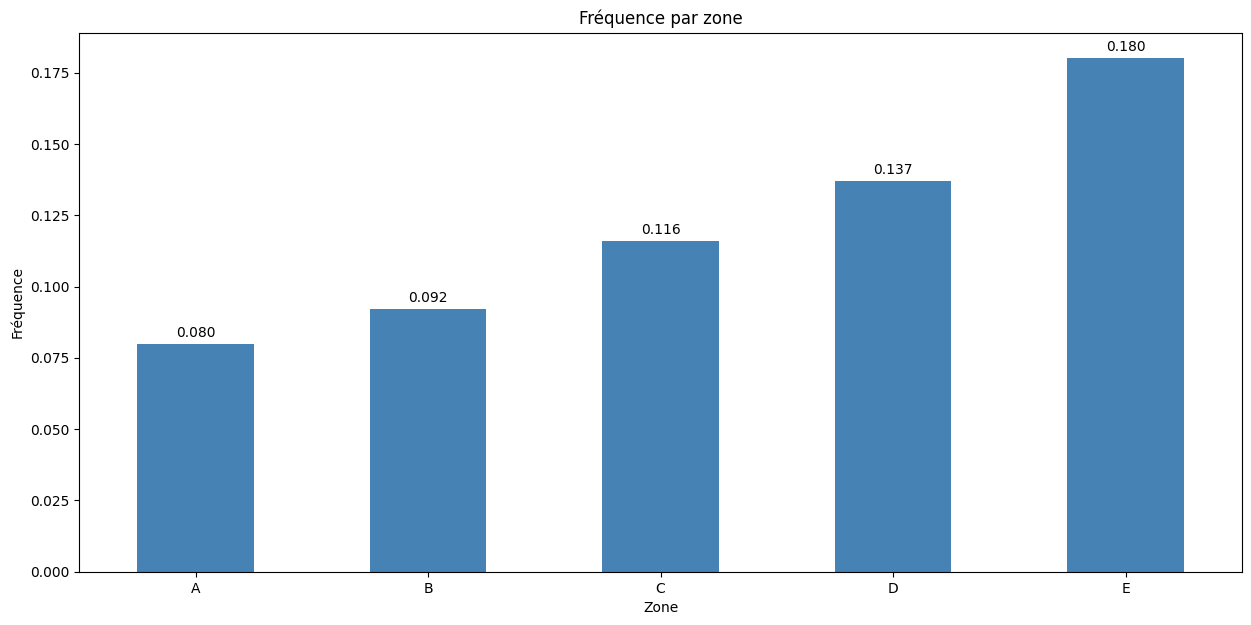

In [11]:
freq_zone = sin.groupby("zone", observed=True).apply(frequence, include_groups=False).round(3)

plt.figure(figsize=(15,7))

ax = freq_zone.plot(kind= "bar", color= "steelblue")
ax.bar_label(ax.containers[0], fmt= "%.3f", padding= 3)

plt.title("Fréquence par zone")
plt.xlabel("Zone")
plt.ylabel("Fréquence")
plt.xticks(rotation=0)
plt.show()

La zone E présente la fréquence de sinistres la plus élevée, tandis que la zone A présente la plus faible. Mais à cette étape, ça ne prouve pas que la zone géographique soit à elle seule responsable de la différence. Voyons maintenant l'autre statistique descriptive: la tranche d'âge.

In [12]:
sin.groupby("tranche_age", observed=True).apply(frequence, include_groups=False).round(3).to_frame("fréquence").T

tranche_age,18-25,26-35,36-50,51-65,66+
fréquence,0.194,0.119,0.11,0.103,0.135


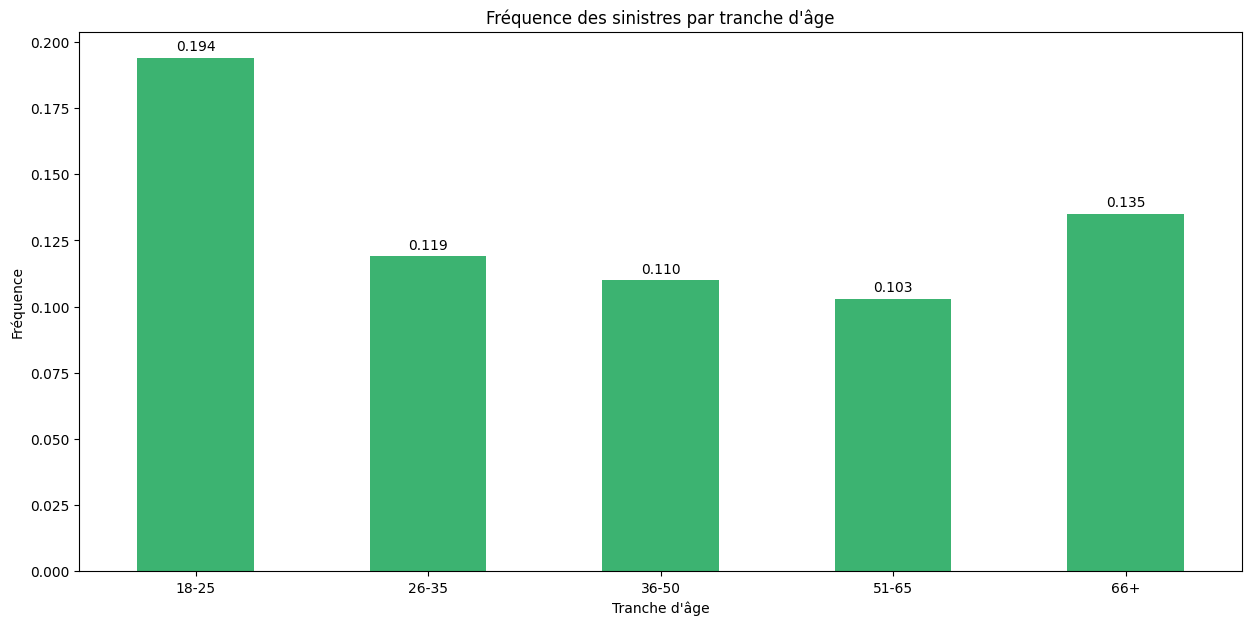

In [13]:
freq_age = sin.groupby("tranche_age", observed=True).apply(frequence, include_groups=False).round(3)

plt.figure(figsize=(15,7))

ax = freq_age.plot(kind= "bar", color= "mediumseagreen")
ax = ax.bar_label(ax.containers[0], fmt = "%.3f", padding= 3)

plt.title("Fréquence des sinistres par tranche d'âge")
plt.ylabel("Fréquence")
plt.xlabel("Tranche d'âge")
plt.xticks(rotation=0)
plt.show()

Pareil que pour la zone géographique, mais on peut voir que les tranches d'âge des 18-25 et des plus de 66 ans présentent les fréquences de sinistres les plus élevées.

In [14]:
sin.head(5)

,id_police,age_conducteur,anciennete_permis,zone,usage,puissance_fiscale,bonus_malus,exposition,prime_annuelle,nb_sinistres,cout_total_sinistres,tranche_age
0,P100000,49.0,30,B,professionnel,9,0.70,0.650,304.84,0,0.00,36-50
1,P100001,25.0,6,A,prive,9,0.91,0.769,352.86,0,0.00,18-25
2,P100002,52.0,27,D,professionnel,9,1.17,0.679,416.00,0,0.00,51-65
3,P100003,25.0,6,C,prive,10,1.07,0.782,367.97,1,2339.27,18-25
4,P100004,45.0,26,C,prive,6,0.62,0.963,412.09,0,0.00,36-50


In [15]:
sin["zone"] = pd.Categorical(sin["zone"], categories=["C", "A", "B", "D", "E"]) #Cat C comme référence.
sin["tranche_age"] = pd.Categorical(sin["tranche_age"], categories=["36-50", "18-25", "26-35", "51-65", "66+"]) #Cat 36-50ans comme référence.

In [16]:
sin.head(5)

,id_police,age_conducteur,anciennete_permis,zone,usage,puissance_fiscale,bonus_malus,exposition,prime_annuelle,nb_sinistres,cout_total_sinistres,tranche_age
0,P100000,49.0,30,B,professionnel,9,0.70,0.650,304.84,0,0.00,36-50
1,P100001,25.0,6,A,prive,9,0.91,0.769,352.86,0,0.00,18-25
2,P100002,52.0,27,D,professionnel,9,1.17,0.679,416.00,0,0.00,51-65
3,P100003,25.0,6,C,prive,10,1.07,0.782,367.97,1,2339.27,18-25
4,P100004,45.0,26,C,prive,6,0.62,0.963,412.09,0,0.00,36-50


In [17]:
glm = smf.glm("nb_sinistres ~ zone + tranche_age + usage + puissance_fiscale",
              data= sin, family= sm.families.Poisson(), exposure= sin["exposition"]).fit()

In [18]:
print(glm.summary().tables[1])

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -2.3404      0.069    -34.076      0.000      -2.475      -2.206
zone[T.A]                 -0.3623      0.074     -4.882      0.000      -0.508      -0.217
zone[T.B]                 -0.2298      0.056     -4.094      0.000      -0.340      -0.120
zone[T.D]                  0.1606      0.050      3.194      0.001       0.062       0.259
zone[T.E]                  0.4355      0.056      7.745      0.000       0.325       0.546
tranche_age[T.18-25]       0.5534      0.059      9.444      0.000       0.439       0.668
tranche_age[T.26-35]       0.0729      0.069      1.062      0.288      -0.062       0.208
tranche_age[T.51-65]      -0.0634      0.048     -1.308      0.191      -0.158       0.032
tranche_age[T.66+]         0.2045      0.061      3.361      0.001       0.085       0.324

Par rapport à la zone C, être en zone E augmente de 0.4355 le logarithme de la fréquence attendue, donc e^0.4355 ≈ 1.54 ; (e^0.43551-1)*100 = 54.57%. La fréquence attendue est supérieur à 54.57% en zone E par rapport à la zone C. Ici on rejette H0 car pvalue < 0.05: effet statistiquement significatif au seuil de 5%.

In [19]:
relativites = pd.DataFrame({
    "Relativité": np.exp(glm.params),
    "IC 2.5%": np.exp(glm.conf_int()[0]),
    "IC 97.5%": np.exp(glm.conf_int()[1]),
}).drop("Intercept")

relativites.round(2)

,Relativité,IC 2.5%,IC 97.5%
zone[T.A],0.70,0.60,0.81
zone[T.B],0.79,0.71,0.89
zone[T.D],1.17,1.06,1.30
zone[T.E],1.55,1.38,1.73
tranche_age[T.18-25],1.74,1.55,1.95
tranche_age[T.26-35],1.08,0.94,1.23
tranche_age[T.51-65],0.94,0.85,1.03
tranche_age[T.66+],1.23,1.09,1.38
usage[T.professionnel],1.21,1.10,1.32
puissance_fiscale,1.01,1.00,1.02


Pour la zone A: fréquence inféreure de 30% par rapport à C.

Pour la tranche d'âge 18-25 ans: la fréquence est supérieur à 74% par rapport à celle des 36-50 ans.

Pour la tranche d'âge 26-35 ans, ce n'est pas significatif au seuil de 5% car l'IC contient 1.

Mais rappel! Les effets que nous avons remontés sont ceteris paribus, la comparaison implique que nous maintenons constants les autres variables du modèle.

In [20]:
risque = pd.concat([pd.Series({"C": 1.0}),
                    np.exp(glm.params.filter(like= "zone")).rename(lambda s: s[-2])])

Ici je récupère les relativités des zones géographiques pour les comparer aux tarifs par la suite.

In [21]:
prime_expo = sin.groupby("zone", observed=True).apply(lambda d: d["prime_annuelle"].sum() / d["exposition"].sum(), include_groups=False)

Et là, on cherche à obtenir pour chaque zone, un montant de prime rapporté à une année d'exposition.

In [22]:
comparaison = pd.DataFrame({
    "risque relatif (GLM)": risque,
    "tarif relatif": prime_expo / prime_expo["C"]
}).loc[list("ABCDE")]

In [23]:
comparaison

,risque relatif (GLM),tarif relatif
A,0.696053,0.894554
B,0.794697,0.954474
C,1.000000,1.000000
D,1.174250,1.057059
E,1.545694,1.134550


Revenons à l'exemple de la Zone E, nous avons expliqué que le modèle estimait 54% de fréquence en plus par rapport à la Zone C. À ça, l'indicateur de tarification (E) est seulement supérieur d'environ 13.5% à celui de C.


On peut donc s'apercevoir que le risque augmente proportionnellement beaucoup plus que le tarif.

Rappelons la formule d'écart de tarification relatif :

$$
\boxed{S_z = \frac{\text{Risque relatif}_z}{\text{Tarif relatif}_z} - 1}
$$


In [24]:
comparaison["sous-tarification"] = comparaison["risque relatif (GLM)"] / comparaison["tarif relatif"] - 1

In [25]:
comparaison.round(4)

,risque relatif (GLM),tarif relatif,sous-tarification
A,0.6961,0.8946,-0.2219
B,0.7947,0.9545,-0.1674
C,1.0000,1.0000,0.0000
D,1.1743,1.0571,0.1109
E,1.5457,1.1346,0.3624


Cela signifie que le risque relatif est environ 36.24% supérieur au tarif relatif pour la zone E.

Exemple avec un profil:

In [26]:
profil = pd.DataFrame({
    "zone": ["E"],
    "tranche_age": ["18-25"],
    "usage": ["professionnel"],
    "puissance_fiscale": [7]
})

In [27]:
freq_profil = glm.predict(profil).iloc[0]

In [28]:
freq_profil_multiple = freq_profil / frequence(sin)

In [29]:
print(f"Fréquence annuelle prédite: {freq_profil:.3f}")
print(f"Fréquence du portefeuille: {frequence(sin):.3f}")
print(f"Risque relatif au portefeuille : {freq_profil_multiple:.2f} fois.")

Fréquence annuelle prédite: 0.332
Fréquence du portefeuille: 0.119
Risque relatif au portefeuille : 2.80 fois.


Fin de l'exemple.

### Passons au Coût Moyen des sinistres.

##### Modélisation du coût moyen des sinistres

L'analyse précédente porte sur la fréquence des sinistres, mais cette dernière ne suffit pas à mesurer le risque financier pour l'assureur. Nous allons donc utiliser un GLM Gamma afin d'estimer le coût moyen des sinistres et compléter l'analyse du risque.

In [30]:
sinistres_pos = sin.query("nb_sinistres > 0").copy() # Je préfère le .query pour les filtres.

In [31]:
sinistres_pos["cout_moyen"] = sinistres_pos["cout_total_sinistres"] / sinistres_pos["nb_sinistres"]

In [32]:
sinistres_pos.head(5)

,id_police,age_conducteur,anciennete_permis,zone,usage,puissance_fiscale,bonus_malus,exposition,prime_annuelle,nb_sinistres,cout_total_sinistres,tranche_age,cout_moyen
3,P100003,25.0,6,C,prive,10,1.07,0.782,367.97,1,2339.27,18-25,2339.27
6,P100006,90.0,70,C,prive,8,0.95,0.753,347.94,1,3112.83,66+,3112.83
7,P100007,45.0,26,C,prive,14,0.98,0.480,232.87,1,1213.18,36-50,1213.18
22,P100022,19.0,0,B,prive,8,1.50,0.883,412.64,1,461.50,18-25,461.50
29,P100029,48.0,27,E,prive,11,1.40,0.844,413.90,1,3305.61,36-50,3305.61


In [33]:
glm_cout = smf.glm("cout_moyen ~ zone + tranche_age + usage",
                   data= sinistres_pos,
                   family= sm.families.Gamma(link= sm.families.links.Log()),
                   var_weights = sinistres_pos["nb_sinistres"]).fit()

Avec le GLM de Poisson, on cherchait à savoir combien de sinistres un conducteur risque d'avoir par an.
Avec le GLM Gamma, on cherche à savoir combien coûte en moyenne un sinistre.

In [34]:
print(f"Coût moyen de référence (C, 36-50 ans, usage privé): {np.exp(glm_cout.params["Intercept"]):,.0f} EUR.")

Coût moyen de référence (C, 36-50 ans, usage privé): 2,936 EUR.


In [35]:
rel_cout = pd.DataFrame({
    "relativité du coût": np.exp(glm_cout.params),
    "pvalue": glm_cout.pvalues
}).drop("Intercept").round(2)
rel_cout

,relativité du coût,pvalue
zone[T.A],1.19,0.18
zone[T.B],0.95,0.63
zone[T.D],1.08,0.39
zone[T.E],1.09,0.39
tranche_age[T.18-25],0.92,0.42
tranche_age[T.26-35],0.77,0.03
tranche_age[T.51-65],1.14,0.12
tranche_age[T.66+],1.04,0.69
usage[T.professionnel],1.01,0.93


Les résultats montrent notamment que les conducteurs de 26 à 35 ans présentent un coût moyen estimé inférieur d'environ 23 % à celui des 36-50 ans. Toutes choses égales par ailleurs, cet effet est statistiquement significatif au seuil de 5 %.

Par contre, les autres variables ne présentent pas d'effet statistiquement significatif à ce seuil. Nous ne pouvons donc pas conclure qu'elles influencent le CM des sinistres sur la base de ces estimations.